# Assignment #6 Perceptron
CSCI 580 Artificial Intelligence, Week 12

**Objective:** Investigate how a single sigmoid neuron learns to classify two groups of points in a two-dimensional feature space.

**Data:** `data.csv` (columns: x1, x2, label)

## Data Loading
Load `data.csv` and plot it.

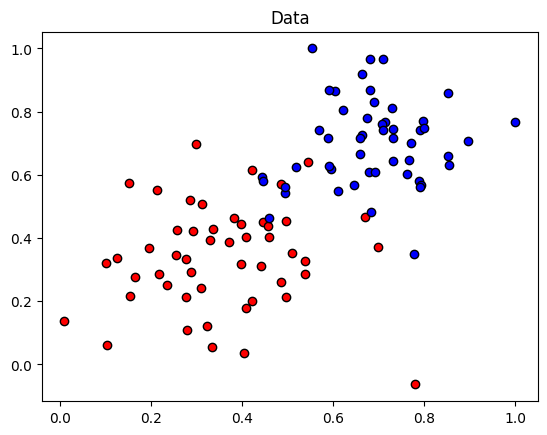

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("data.csv", delimiter=",")
X = data[:, :2]   #two numbers for each of the dots(x1, x2)
y = data[:, 2]    # the right answer for each dot(1 = red, 0 = blue)

def plot_dots():
    plt.scatter(X[y==1, 0], X[y==1, 1], c="red", edgecolor="k")
    plt.scatter(X[y==0, 0], X[y==0, 1], c="blue", edgecolor="k")

def draw_line(w, b, style, color):
    x = np.array([-0.05, 1.05])
    plt.plot(x, -(w[0]*x + b) / w[1], style, color=color)   #line where w1*x + w2*y + b = 0

plot_dots()
plt.title("Data")
plt.show()

## Part 1: Heuristic approach
1. Start a perceptron with random weights and bias: w1, w2, ..., wn, b
2. For each of all points (data) with their corresponding labels (answers):
   - Classify according to the perceptron
   - For a misclassified point:
     - If classification == 0: b + r -> b; for all wi: wi + r*xi -> wi
     - If classification == 1: b - r -> b; for all wi: wi - r*xi -> wi
3. Repeat #2 enough number of times

Plot the initial line as **red**, subsequent ones after each iteration as dashed **green**, and the last one as **black**. Play with the learning rate.

lr = 0.01  epochs = 65  wrong = 26 out of 100


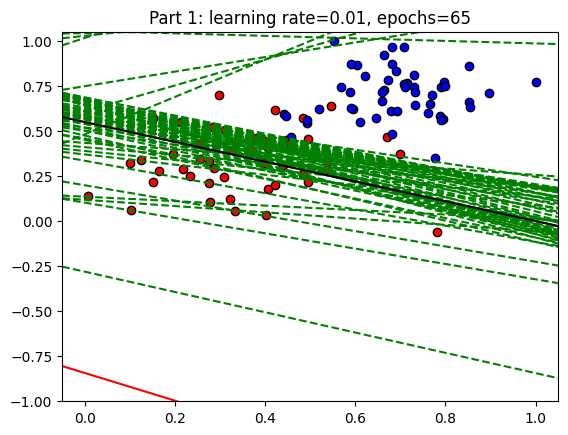

lr = 0.1  epochs = 65  wrong = 20 out of 100


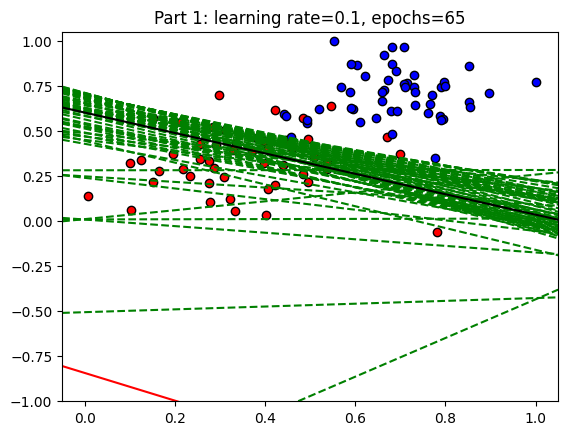

lr = 1  epochs = 65  wrong = 8 out of 100


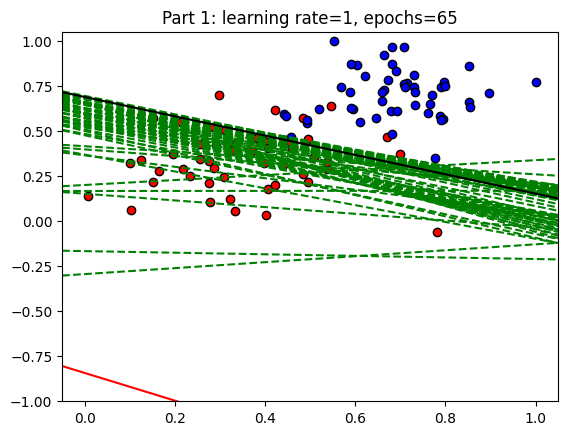

lr = 0.1  epochs = 10  wrong = 43 out of 100


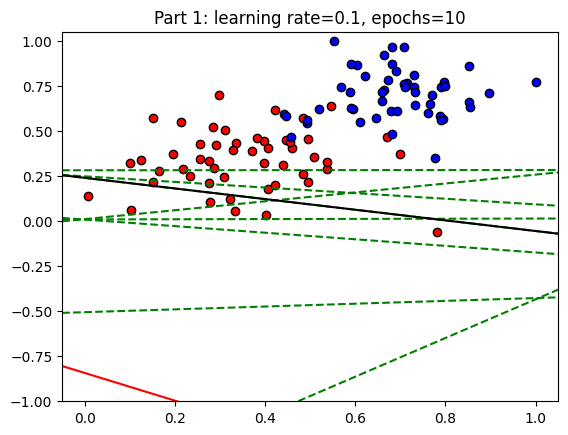

In [2]:
def part1(lr, epochs):
    np.random.seed(0)
    w = np.random.rand(2)   #random start
    b = np.random.rand()
    plot_dots()
    draw_line(w, b, "-", "red")              #first line is red
    for e in range(epochs):
        for i in range(len(X)):
            guess = 1 if w @ X[i] + b >= 0 else 0    #guess 0 or 1
            if guess != y[i]:                        #fix only if wrong
                if guess == 0:
                    b = b + lr                       #should be 1 -> add
                    w = w + lr * X[i]
                else:
                    b = b - lr                       # should be 0, subtract
                    w = w - lr * X[i]
        draw_line(w, b, "--", "green")           #line after each pass= dashed green
    draw_line(w, b, "-", "black")                #last line = black
    plt.xlim(-0.05, 1.05); plt.ylim(-1.0, 1.05)   #lower bottom so the red start line shows
    plt.title(f"Part 1: learning rate={lr}, epochs={epochs}")
    guesses = (X @ w + b >= 0)                    #guess for every dot
    wrong = np.sum(guesses != y)                  #count the wrong ones
    print("lr =", lr, " epochs =", epochs, " wrong =", wrong, "out of", len(y))
    plt.show()

part1(0.01, 65)
part1(0.1, 65)
part1(1, 65)
part1(0.1, 10)    #fewer epochs

## Part 1 Analysis
1. The line starts in a random place and then moves towards the gap between the red and blue.
2. There is a small learning rate of 0.01 and the line moves in small steps so it is slow
3. The big learning rate is 1 and the line moves in big jumps so it is fast but jumpy
4. with only 10 epochs the line has less time to move resulting in it ending in the wrong place with 43 wrong out of 100
5. It never gets every single dot correct, there are 65 epochs and 8 to 26 mistakes where 8 at learning rate 1 is the best. This is because a few red and blue dots overlap.

## Part 2: Gradient descent (sigmoid neuron)
1. Start a perceptron with random weights and bias: w1, w2, ..., wn, b
2. For each of all points (data) with their corresponding labels (answers):
   - Compute prediction output (y_hat)
   - Compute error function (y - y_hat)
   - b + r(y - y_hat) -> b
   - For all wi: wi + r(y - y_hat)xi -> wi
3. Repeat #2 until error is sufficiently small

Play with learning rate and number of epochs. Plot the boundary (red initial, dashed green subsequent, black last). Compute log loss and plot the error graph every 10 epochs.

lr = 0.01  epochs = 100  wrong = 7 out of 100


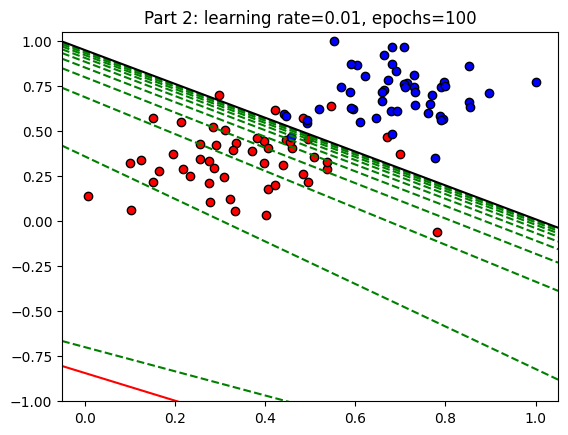

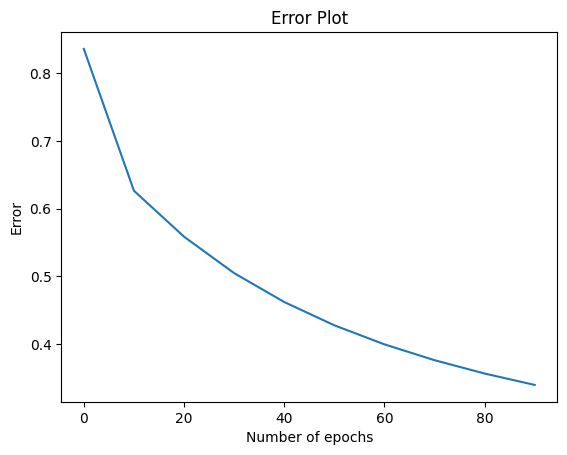

lr = 0.1  epochs = 100  wrong = 7 out of 100


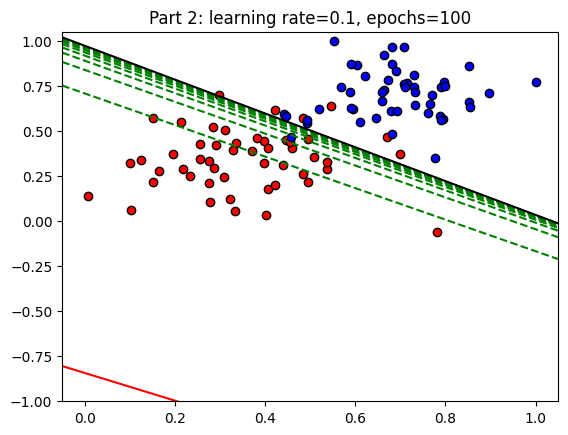

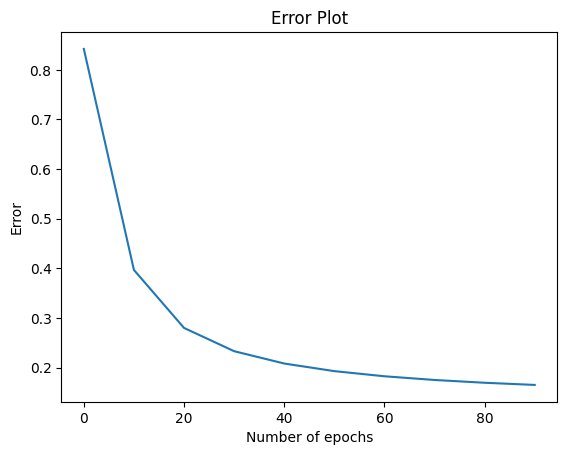

lr = 1  epochs = 100  wrong = 7 out of 100


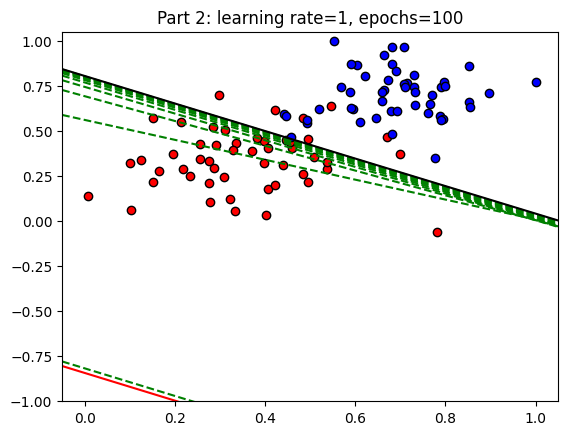

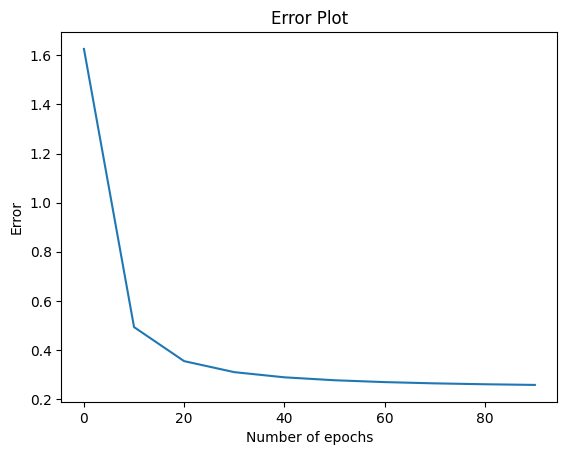

lr = 0.1  epochs = 1000  wrong = 6 out of 100


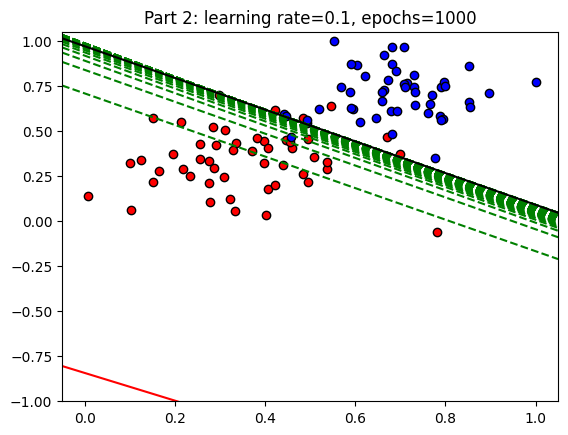

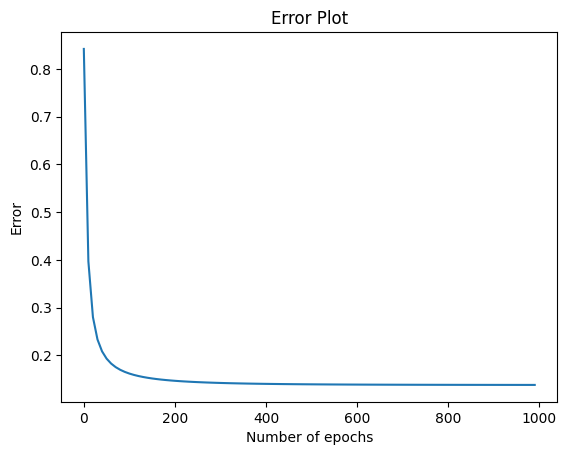

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def part2(lr, epochs):
    np.random.seed(0)
    w = np.random.rand(2)
    b = np.random.rand()
    errors, epoch_list = [], []
    plot_dots()
    draw_line(w, b, "-", "red")              #first line = red
    for e in range(epochs):
        for i in range(len(X)):
            y_hat = sigmoid(w @ X[i] + b)     #guess between 0 and 1
            error = y[i] - y_hat                 #how wrong the guess was
            b = b + lr * error
            w = w + lr * error * X[i]
        if e % 10 == 0:                          #every 10 epochs
            draw_line(w, b, "--", "green")
            p = sigmoid(X @ w + b)
            loss = -np.mean(y*np.log(p) + (1-y)*np.log(1-p)) #log loss = the error number
            errors.append(loss)
            epoch_list.append(e)
    draw_line(w, b, "-", "black")                #last line = black
    plt.xlim(-0.05, 1.05); plt.ylim(-1.0, 1.05)   #lower bottom so the red start line shows
    plt.title(f"Part 2: learning rate={lr}, epochs={epochs}")
    guesses = (sigmoid(X @ w + b) >= 0.5)         #guess for every dot
    wrong = np.sum(guesses != y)                  #count the wrong ones
    print("lr =", lr, " epochs =", epochs, " wrong =", wrong, "out of", len(y))
    plt.show()

    plt.plot(epoch_list, errors)                 #error graph
    plt.xlabel("Number of epochs"); plt.ylabel("Error"); plt.title("Error Plot")
    plt.show()

part2(0.01, 100)
part2(0.1, 100)
part2(1, 100)
part2(0.1, 1000)

## Part 2 Analysis
1. This version also moves the line by a little each time, but it moves it more when it is more wrong
2. the error graph goes down and this means the line is getting better
3. the smaller learning rate os 0.01 is too slow and the error is still going down at the end at 0.34
4. a medium learning rate of 0.1 worked best because it reached the lowest error, about 0.17 after 100 epochs
5. A big learning rate of 1 starts with a high error of 1.6 because the steps are too big, but then it goes down smoothly.
6. More epochs helps at first and then barely helps. Having 1000 epochs which is about 0.14 is only a little better then 100(0.17)
7. The accuracy stays around 93% because a few of the red and blue dots overlap